<a href="https://colab.research.google.com/github/Resh-ma050706/Deep-learning/blob/main/EX_7_Text_Preprocessing_and_Embedding_Generation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q nltk gensim numpy matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 52.4 MB/s eta 0:00:00


In [4]:
import re
import string
import numpy as np
import matplotlib.pyplot as plt

import nltk
from nltk.corpus import brown, stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from nltk.probability import FreqDist

from gensim.models import Word2Vec

# ---- CHANGE THIS TO YOUR ROLL NUMBER(S) ----
ROLL_NO = "24BAD097"
# --------------------------------------------

for pkg in ["brown", "stopwords", "punkt", "punkt_tab", "wordnet", "omw-1.4"]:
    nltk.download(pkg, quiet=True)

print("Roll No:", ROLL_NO)
print("NLTK version:", nltk.__version__)

Roll No: 24BAD097
NLTK version: 3.9.1


## PART A: DATASET PREPARATION AND TEXT PREPROCESSING

In [3]:
print("Roll No:", ROLL_NO)

# 1. Load the Brown Corpus and pick a category
print("Available categories:", brown.categories())
CATEGORY = "news"

raw_sentences = brown.sents(categories=CATEGORY)       # list of token lists
print("\nSelected category :", CATEGORY)
print("Number of sentences:", len(raw_sentences))

Roll No: YOUR_ROLL_NO
Available categories: ['adventure', 'belles_lettres', 'editorial', 'fiction', 'government', 'hobbies', 'humor', 'learned', 'lore', 'mystery', 'news', 'religion', 'reviews', 'romance', 'science_fiction']

Selected category : news
Number of sentences: 4623


In [5]:
print("Roll No:", ROLL_NO)

# 2. Examine sample sentences
for i in range(5):
    print(f"Sentence {i+1}: {' '.join(raw_sentences[i])}\n")

Roll No: 24BAD097
Sentence 1: The Fulton County Grand Jury said Friday an investigation of Atlanta's recent primary election produced `` no evidence '' that any irregularities took place .

Sentence 2: The jury further said in term-end presentments that the City Executive Committee , which had over-all charge of the election , `` deserves the praise and thanks of the City of Atlanta '' for the manner in which the election was conducted .

Sentence 3: The September-October term jury had been charged by Fulton Superior Court Judge Durwood Pye to investigate reports of possible `` irregularities '' in the hard-fought primary which was won by Mayor-nominate Ivan Allen Jr. .

Sentence 4: `` Only a relative handful of such reports was received '' , the jury said , `` considering the widespread interest in the election , the number of voters and the size of this city '' .

Sentence 5: The jury said it did find that many of Georgia's registration and election laws `` are outmoded or inadequate

In [6]:
print("Roll No:", ROLL_NO)

stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def preprocess(sentence_text):
    # lowercase
    text = sentence_text.lower()
    # word tokenization
    tokens = word_tokenize(text)
    # remove punctuation (and tokens with no alphabetic characters, e.g. numbers, `` and '')
    tokens = [t for t in tokens if t not in string.punctuation and t.isalpha()]
    # remove stop words
    tokens = [t for t in tokens if t not in stop_words]
    # lemmatization
    tokens = [lemmatizer.lemmatize(t) for t in tokens]
    return tokens

# 3-7. Apply the full pipeline to every sentence
original_sentences = [" ".join(s) for s in raw_sentences]
processed_sentences = [preprocess(s) for s in original_sentences]

# drop sentences that became too short to give any context
processed_sentences = [s for s in processed_sentences if len(s) > 1]

print("Sentences after preprocessing:", len(processed_sentences))

Roll No: 24BAD097
Sentences after preprocessing: 4512


In [7]:
print("Roll No:", ROLL_NO)

# Display original vs. preprocessed text
for i in range(5):
    print(f"Original     : {original_sentences[i]}")
    print(f"Preprocessed : {preprocess(original_sentences[i])}")
    print("-" * 100)

Roll No: 24BAD097
Original     : The Fulton County Grand Jury said Friday an investigation of Atlanta's recent primary election produced `` no evidence '' that any irregularities took place .
Preprocessed : ['fulton', 'county', 'grand', 'jury', 'said', 'friday', 'investigation', 'atlanta', 'recent', 'primary', 'election', 'produced', 'evidence', 'irregularity', 'took', 'place']
----------------------------------------------------------------------------------------------------
Original     : The jury further said in term-end presentments that the City Executive Committee , which had over-all charge of the election , `` deserves the praise and thanks of the City of Atlanta '' for the manner in which the election was conducted .
Preprocessed : ['jury', 'said', 'presentment', 'city', 'executive', 'committee', 'charge', 'election', 'deserves', 'praise', 'thanks', 'city', 'atlanta', 'manner', 'election', 'conducted']
--------------------------------------------------------------------------

## PART B: VOCABULARY GENERATION AND WORD FREQUENCY ANALYSIS

In [8]:
print("Roll No:", ROLL_NO)

# 1. Create vocabulary from the preprocessed text
all_words = [w for sent in processed_sentences for w in sent]
vocabulary = sorted(set(all_words))

# 2. Word frequencies with FreqDist
fdist = FreqDist(all_words)

print("Total tokens   :", len(all_words))
print("Vocabulary size:", len(vocabulary))
print("Sample vocabulary:", vocabulary[:20])

Roll No: 24BAD097
Total tokens   : 47604
Vocabulary size: 9885
Sample vocabulary: ['aaron', 'abandoned', 'abandonment', 'abatuno', 'abbey', 'abe', 'abel', 'abell', 'abide', 'ability', 'ablaze', 'able', 'abner', 'aboard', 'abolish', 'abolition', 'abortive', 'abra', 'abraham', 'abroad']


In [9]:
print("Roll No:", ROLL_NO)

# 3. Ten most frequent words
top10 = fdist.most_common(10)
print("Top 10 most frequent words:")
for rank, (word, count) in enumerate(top10, 1):
    print(f"{rank:>2}. {word:<12} {count}")

Roll No: 24BAD097
Top 10 most frequent words:
 1. said         406
 2. year         260
 3. would        249
 4. new          241
 5. state        223
 6. one          222
 7. last         177
 8. two          174
 9. first        158
10. president    155


Roll No: 24BAD097


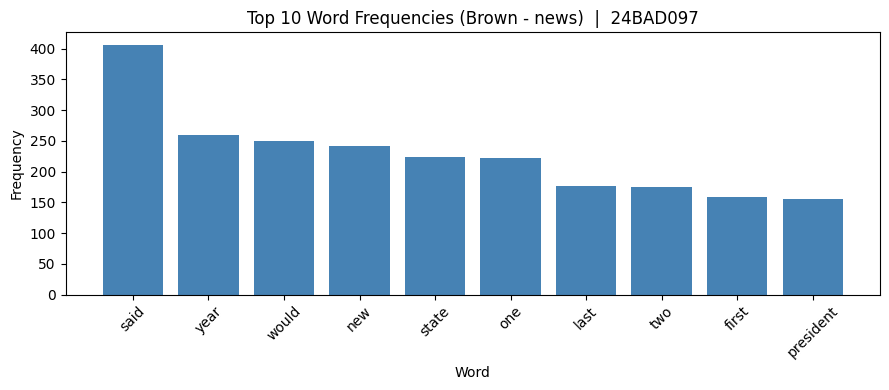

<Axes: title={'center': 'Cumulative Frequency (Top 30) | 24BAD097'}, xlabel='Samples', ylabel='Cumulative Counts'>

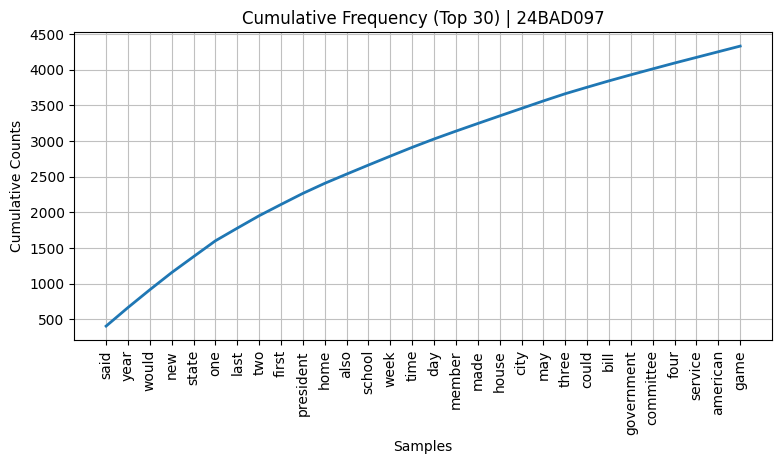

In [10]:
print("Roll No:", ROLL_NO)

# 4. Frequency distribution plot
words, counts = zip(*top10)
plt.figure(figsize=(9, 4))
plt.bar(words, counts, color="steelblue")
plt.title(f"Top 10 Word Frequencies (Brown - {CATEGORY})  |  {ROLL_NO}")
plt.xlabel("Word")
plt.ylabel("Frequency")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# cumulative frequency distribution of top 30 words
plt.figure(figsize=(9, 4))
fdist.plot(30, cumulative=True, title=f"Cumulative Frequency (Top 30) | {ROLL_NO}")

In [11]:
print("Roll No:", ROLL_NO)

# 5. Tokenized sentences prepared for Word2Vec training
sentences_for_w2v = processed_sentences
print("Number of training sentences:", len(sentences_for_w2v))
print("Example training sentence   :", sentences_for_w2v[0])

Roll No: 24BAD097
Number of training sentences: 4512
Example training sentence   : ['fulton', 'county', 'grand', 'jury', 'said', 'friday', 'investigation', 'atlanta', 'recent', 'primary', 'election', 'produced', 'evidence', 'irregularity', 'took', 'place']


## PART C: WORD EMBEDDING GENERATION USING WORD2VEC

In [12]:
print("Roll No:", ROLL_NO)

# 1-2. Train Word2Vec: Skip-gram (sg=1), vector size 100, window 5
model = Word2Vec(
    sentences=sentences_for_w2v,
    vector_size=100,   # embedding dimension
    window=5,          # context window size
    min_count=2,       # ignore words that occur only once
    sg=1,              # 1 = Skip-gram, 0 = CBOW
    workers=4,
    epochs=30,
    seed=42,
)

print("Model trained.")
print("Vocabulary size in Word2Vec:", len(model.wv.key_to_index))
print("Embedding dimension        :", model.wv.vector_size)

Roll No: 24BAD097
Model trained.
Vocabulary size in Word2Vec: 5155
Embedding dimension        : 100


In [13]:
print("Roll No:", ROLL_NO)

# 3-4. Embedding vector for a selected word
def pick_word(candidates):
    for w in candidates:
        if w in model.wv.key_to_index:
            return w
    return model.wv.index_to_key[0]   # fallback: most frequent word

selected_word = pick_word(["president", "state", "year", "city"])
vector = model.wv[selected_word]

print("Selected word    :", selected_word)
print("Vector dimensions:", vector.shape)
print("First 10 values  :", np.round(vector[:10], 4))
print("\nFull embedding vector:\n", vector)

Roll No: 24BAD097
Selected word    : president
Vector dimensions: (100,)
First 10 values  : [-0.8503 -0.806  -0.4978  1.2299 -0.1637  0.2812 -0.2906  0.1934  0.081
 -0.3584]

Full embedding vector:
 [-0.8502649  -0.80601054 -0.49777207  1.2298808  -0.16373047  0.28123134
 -0.29063722  0.19336058  0.08096798 -0.35835758  0.00832866  0.6494431
  0.15085995  0.9586698  -0.50928575 -0.16770053  0.54869336  0.5532855
 -0.277837    0.03765145  0.5666142   0.67437845  0.69871646  0.129496
  0.16286503  0.406386    0.15128157  0.33073068  0.0541632  -0.41941404
 -0.2599125   0.7114433   0.07088454  0.56774604  0.2307771   1.0057015
 -0.64356077 -0.70467114 -0.22193858  0.148885    0.35784012 -0.59431905
  0.9941865   0.11308686 -0.7078732  -0.1519006   0.88097924 -0.11617528
  0.99995106 -0.8158625  -0.26731297 -0.79930085  0.7132305  -0.20903052
  0.7973998   0.34555045 -0.12913299  0.70889384  0.32644147 -0.11660952
 -0.06442604  0.04875489  0.8485763   0.44267246  0.9656034   0.06247732
 -0

In [14]:
print("Roll No:", ROLL_NO)

# 5. Five most similar words
print(f"Top 5 words most similar to '{selected_word}':\n")
for word, score in model.wv.most_similar(selected_word, topn=5):
    print(f"{word:<15} cosine similarity = {score:.4f}")

# a few more words for exploration
for w in ["city", "school", "house"]:
    if w in model.wv.key_to_index:
        print(f"\nTop 5 similar to '{w}':")
        for word, score in model.wv.most_similar(w, topn=5):
            print(f"   {word:<15} {score:.4f}")

Roll No: 24BAD097
Top 5 words most similar to 'president':

inauguration    cosine similarity = 0.5871
vice            cosine similarity = 0.5690
retired         cosine similarity = 0.5496
stevenson       cosine similarity = 0.5390
chen            cosine similarity = 0.5361

Top 5 similar to 'city':
   kansa           0.7676
   mo              0.7471
   cd              0.6994
   expressed       0.6705
   animal          0.6506

Top 5 similar to 'school':
   require         0.6959
   teacher         0.6518
   deaf            0.6293
   hay             0.6085
   permitting      0.6064

Top 5 similar to 'house':
   fitted          0.7089
   salinger        0.6809
   letitia         0.6781
   compromise      0.6759
   pierre          0.6607


## PART D: WORD SIMILARITY ANALYSIS AND EXPERIMENT MANAGEMENT

In [15]:
print("Roll No:", ROLL_NO)

# 1. Three meaningful word pairs (pairs not found in the vocabulary are skipped automatically)
candidate_pairs = [
    ("president", "house"),
    ("city", "state"),
    ("school", "student"),
    ("year", "month"),
    ("man", "woman"),
    ("team", "game"),
    ("court", "judge"),
    ("county", "city"),
]
pairs = [(a, b) for a, b in candidate_pairs
         if a in model.wv.key_to_index and b in model.wv.key_to_index][:3]
print("Selected word pairs:", pairs)

Roll No: 24BAD097
Selected word pairs: [('president', 'house'), ('city', 'state'), ('school', 'student')]


In [16]:
print("Roll No:", ROLL_NO)

# 2. Cosine similarity for each pair
def cosine_sim(u, v):
    return float(np.dot(u, v) / (np.linalg.norm(u) * np.linalg.norm(v)))

results = []
print(f"{'Word 1':<12}{'Word 2':<12}{'Gensim':>10}{'Manual (NumPy)':>18}")
print("-" * 52)
for a, b in pairs:
    g = float(model.wv.similarity(a, b))
    m = cosine_sim(model.wv[a], model.wv[b])
    results.append((a, b, g))
    print(f"{a:<12}{b:<12}{g:>10.4f}{m:>18.4f}")

# 3. Most similar pair
best = max(results, key=lambda x: x[2])
worst = min(results, key=lambda x: x[2])
print(f"\nMost similar pair : ({best[0]}, {best[1]})  ->  {best[2]:.4f}")
print(f"Least similar pair: ({worst[0]}, {worst[1]})  ->  {worst[2]:.4f}")

Roll No: 24BAD097
Word 1      Word 2          Gensim    Manual (NumPy)
----------------------------------------------------
president   house           0.1432            0.1432
city        state           0.1089            0.1089
school      student         0.4206            0.4206

Most similar pair : (school, student)  ->  0.4206
Least similar pair: (city, state)  ->  0.1089


Roll No: 24BAD097


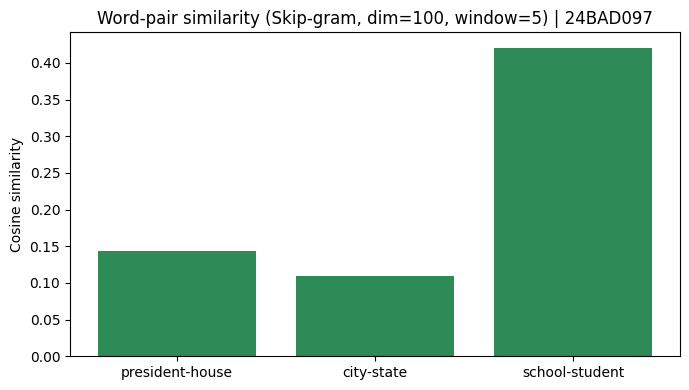

In [17]:
print("Roll No:", ROLL_NO)

# Visual comparison of the similarity scores
labels = [f"{a}-{b}" for a, b, _ in results]
scores = [s for _, _, s in results]
plt.figure(figsize=(7, 4))
plt.bar(labels, scores, color="seagreen")
plt.ylabel("Cosine similarity")
plt.title(f"Word-pair similarity (Skip-gram, dim=100, window=5) | {ROLL_NO}")
plt.tight_layout()
plt.show()

Roll No: 24BAD097


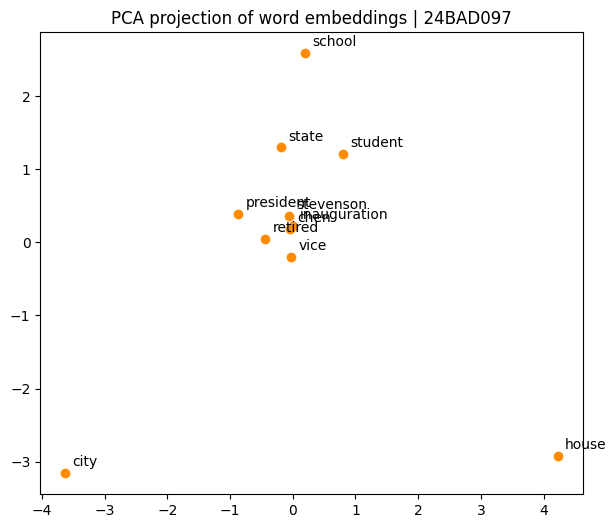

In [18]:
print("Roll No:", ROLL_NO)

# Optional: 2-D visualisation of embeddings using PCA
from sklearn.decomposition import PCA

words_to_plot = list({w for pair in pairs for w in pair} | set(w for w, _ in model.wv.most_similar(selected_word, topn=5)) | {selected_word})
X = np.array([model.wv[w] for w in words_to_plot])
X2 = PCA(n_components=2).fit_transform(X)

plt.figure(figsize=(7, 6))
plt.scatter(X2[:, 0], X2[:, 1], color="darkorange")
for (x, y), w in zip(X2, words_to_plot):
    plt.annotate(w, (x, y), textcoords="offset points", xytext=(5, 5))
plt.title(f"PCA projection of word embeddings | {ROLL_NO}")
plt.show()